# Imports

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats #(not in environment yet?)
import sys
from statsmodels.stats.multicomp import pairwise_tukeyhsd #(not in envirnoment yet)
import seaborn as sns
# from statannotations.Annotator import Annotator

# Loading Data
Loading one single datafile using pandas, concatenatin all data files into one big table to analyse together

## Looping over all datafiles and concatenating them

In [3]:
# how can I concatenate all files within a certain folder path without loading a single file first

behav_data_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/behavioural_outputfiles"
sys.path.append(behav_data_path)

df_list = []
for file_name in os.listdir(behav_data_path):
    if file_name.endswith(".txt") and "pr.txt" not in file_name and not file_name.startswith("resultfile_pil"):  # Check if the file has .txt extension
        file_path = os.path.join(behav_data_path, file_name)
  
        # Read the file and determine whether to skip rows based on numerical content
        data = pd.read_table(file_path, skipinitialspace=True)
        has_numerical_content = data.applymap(lambda x: isinstance(x, (int, float))).any(axis=1)
        
        # Exclude rows with no numerical content
        data = data[has_numerical_content]
        
        df_list.append(data)

# Concatenate all DataFrames in the list
df = pd.concat(df_list, ignore_index=True)

## Binomial Tests of Accuracy

### Binomial Test of All Conditions

In [4]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data = df.loc[df['subID'] == i, 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data)

    trials = len(participant_data)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion)
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print(f"  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.4948
  Correct Responses = 285 out of 576
  Binomial Test (k=285, n=576, p-value=0.8350)
  Interpretation: Not Significant
There were 1 elements in the results


### Binomial Test Condition 1

In [5]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data1.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data1)

    trials = len(participant_data1)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant Z16JQR:
  Mean Accuracy = 0.8385
  Correct Responses = 161 out of 192
  Binomial Test (k=161, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.7292
  Correct Responses = 140 out of 192
  Binomial Test (k=140, n=192, p-value=0.0000)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.8958
  Correct Responses = 172 out of 192
  Binomial Test (k=172, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.9010
  Correct Responses = 173 out of 192
  Binomial Test (k=173, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.8125
  Correct Responses = 156 out of 192
  Binomial Test (k=156, n=192, p-value=0.0000)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant ZGV9KP:
  Mean Accuracy = 0.8229
 

### Binomial Test Condition 2

In [6]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data2 = df.loc[(df['subID'] == i) & (df['items_presented'] == 2), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data2.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data2)

    trials = len(participant_data2)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.5156
  Correct Responses = 99 out of 192
  Binomial Test (k=99, n=192, p-value=0.7183)
  Interpretation: Not Significant
Participant 6TQVJE:
  Mean Accuracy = 0.5677
  Correct Responses = 109 out of 192
  Binomial Test (k=109, n=192, p-value=0.0709)
  Interpretation: Not Significant
Participant 30K8XE:
  Mean Accuracy = 0.5521
  Correct Responses = 106 out of 192
  Binomial Test (k=106, n=192, p-value=0.1701)
  Interpretation: Not Significant
There were 3 elements in the results


### Binomial Test Condition 3

In [7]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data3 = df.loc[(df['subID'] == i) & (df['items_presented'] == 3), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data3.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data3)

    trials = len(participant_data3)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either

Participant Z16JQR:
  Mean Accuracy = 0.7448
  Correct Responses = 143 out of 192
  Binomial Test (k=143, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.7135
  Correct Responses = 137 out of 192
  Binomial Test (k=137, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.5573
  Correct Responses = 107 out of 192
  Binomial Test (k=107, n=192, p-value=0.1294)
  Interpretation: Not Significant
Participant ZGV9KP:
  Mean Accuracy = 0.67

## Adding Columns for later use

### Adding Column for mask

In [8]:
df['mask'] = 0

df.loc[df['onset_mask'].notna() & (df['onset_mask'] > 0), 'mask'] = 1

### Adding Column for Button Press

In [9]:
# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be seen in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed


# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

### Adding column for stimuli subset

In [10]:
# Define the stimuli sets
stimuli_set1 = ['01_pitcher02a_BOSS.jpg', '01_lighthouse.jpg', '01_table03.jpg']
stimuli_set2 = ['02_crown.jpg', '02_candelabra.jpg', '02_photoshopTelephone.jpg']
stimuli_set3 = ['03_gazebo.jpg', '03_radio03a.jpg', '03_lamppost01.jpg']

# Function to determine the stimuli set based on 'object_1_name'
def determine_stimuli_set(row):
    object_name = row['object_1_name']
    if object_name in stimuli_set1:
        return 'stimuli_set1'
    elif object_name in stimuli_set2:
        return 'stimuli_set2'
    elif object_name in stimuli_set3:
        return 'stimuli_set3'
    else:
        return 'Unknown'  # You can change this to whatever value you prefer for other cases

# Use the apply() method to create the 'stimuli_set' column
df['stimuli_set'] = df.apply(determine_stimuli_set, axis=1)

### Column names as variables

In [11]:
columns = df.columns
column_names = df.columns.tolist()

# Descriptive Statistics before Exclusion

In [12]:
# Number of participants *before* exclusion
len_partis = len(partis)
print(f'There were {len_partis} participants in the original dataset.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
sd_age = age_by_sub_id.std()
print(f'The mean age of participants was {mean_age:.2f} with the standard deviation of {sd_age:.2f}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 43 participants in the original dataset.
Count of male Participants: 12
Proportion of male participants: 0.27906976744186046
The mean age of participants was 25.53 with the standard deviation of 4.59
There were 21 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 15 with stimuli set 2, and 13 with stimuli set 3.


## Excluding Participants

In [13]:
# List of subject IDs to exclude

# do we really need to exclue square mask?
subjects_to_exclude = ['OUGX64', 'UCXTVD', 'D62XJG']

# Use boolean indexing to drop rows where 'subID' is in the exclusion list
df = df[~df['subID'].isin(subjects_to_exclude)]

good_partis = df['subID'].unique()

# Descriptive Statistics after Exclusion

In [14]:
# Number of participants after exclusion
good_partis = df['subID'].unique()
len_good_partis = len(good_partis)
print(f'There were {len_good_partis} participants in the dataset that went into the final analysis.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(good_partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
print(f'The mean age of participants was: {mean_age}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 40 participants in the dataset that went into the final analysis.
Count of male Participants: 12
Proportion of male participants: 0.3
The mean age of participants was: 25.525
There were 18 Participants that had the Version of the task including the mask and 22 without the mask.
There were 14 Participants tested with stimuli set 1, 13 with stimuli set 2, and 13 with stimuli set 3.


# Confidence / Manipulation / Accuracy Checks

## Mask vs. No Mask 

In [15]:
# Mask vs no Mask
mask_data = df.loc[df['mask'] == 1, 'acc_trial_concrete_cued']
nomask_data = df.loc[df['mask'] == 0, 'acc_trial_concrete_cued']

# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(mask_data, nomask_data)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between the mask version and the no-mask version.")
else:
    print("The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.")


T-Test Results:
T-statistic: 0.8476542347936279
p-value: 0.39663936667843813
The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.


## Upside down vs upright accuracy

In [16]:

# these give a boolean value (True/False)

#ud = (ud <= 270 and ud >= 90)
upside_down = (df['object_test_rot_cued'] < 270) & (df['object_test_rot_cued'] > 90)
upright = (df['object_test_rot_cued'] < 90) | (df['object_test_rot_cued'] > 270)
#upside_down = df['object_test_rot_cued'] ('object_test_rot_cued' <= 270) and ('object_test_rot_cued' >= 90)
# could probably do with only one variable and just check wether its true or false
# 180° is not the upright position necessarily, where does the circle start?
#upright = df['object_test_rot_cued'] == ud = (ud <= 270 and ud >= 90)

# might have to be upright= true or something

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)


# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(upside_down, upright)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7235079171741778
0.7031006409146024
T-Test Results:
T-statistic: 0.48447211499487897
p-value: 0.628053152331383
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


## Mean accuracy by condition, oneway ANOVA

### Assumtions met?!

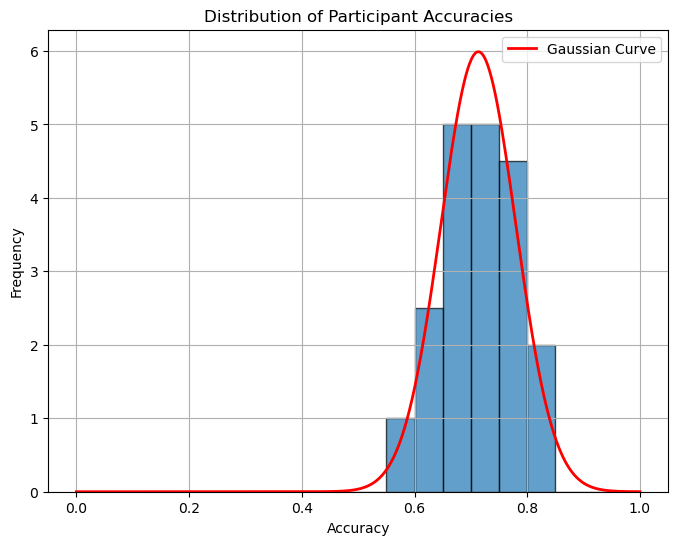

In [17]:
accuracy_per_participant = df.groupby('subID')['acc_trial_concrete_cued'].mean()
accuracy_range = (0, 1)

plt.figure(figsize=(8, 6))  # Set the figure size
# Create the histogram
hist, bins, _ = plt.hist(accuracy_per_participant, bins=20, range=accuracy_range, edgecolor='k', alpha=0.7, density=True)

# Calculate the mean and standard deviation of the data
mean = np.mean(accuracy_per_participant)
std_dev = np.std(accuracy_per_participant)

# Create a range of x values for the Gaussian curve
x = np.linspace(accuracy_range[0], accuracy_range[1], 1000)

# Calculate the corresponding y values for the Gaussian curve
y = stats.norm.pdf(x, mean, std_dev)

# Plot the Gaussian curve
plt.plot(x, y, 'r-', lw=2, label='Gaussian Curve')

# Add labels and a title
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
plt.title('Distribution of Participant Accuracies')

# Show gridlines (optional)
plt.grid(True)

# Add a legend
plt.legend()

# Show the plot
plt.show()

In [18]:

# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print("Mean accuracy per condition:", mean_cond)
mean_acc = df['acc_trial_concrete_cued'].mean()
print(mean_acc)

condition_means = mean_cond.tolist()
# why do I have the following line?
condition_labels = ['1', '2', '3']
# these turn out to be exactly the same size, I am a little suspicious that I indeed have exactly the same number of accuracy lines for every condition
# can remove this later, but might be interesting to check the number of samples per condition after I decide which participants to exclude
# len_sample_con1 = len(df[df['items_presented'] == 1])
# print('samples con1:', len_sample_con1)
# len_sample_con2 = len(df[df['items_presented'] == 2])
# print('samples con1:', len_sample_con2)
# len_sample_con3 = len(df[df['items_presented'] == 3])
# print('samples con1:', len_sample_con3)

acc_con1 = df.loc[df['items_presented'] == 1, 'acc_trial_concrete_cued']
acc_con2 = df.loc[df['items_presented'] == 2, 'acc_trial_concrete_cued']
acc_con3 = df.loc[df['items_presented'] == 3, 'acc_trial_concrete_cued']

# Perform one-way ANOVA
f_statistic, p_value = stats.f_oneway(acc_con1, acc_con2, acc_con3)

# Define the significance level (alpha)
alpha = 0.05

# Print the ANOVA results
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The one-way ANOVA indicates a significant difference among the three conditions.")
else:
    print("The one-way ANOVA does not indicate a significant difference among the three conditions.")

Mean accuracy per condition: items_presented
1    0.795964
2    0.691146
3    0.652734
Name: acc_trial_concrete_cued, dtype: float64
0.71328125
ANOVA Results:
F-statistic: 199.44524761511596
p-value: 1.3285811326735942e-86
The one-way ANOVA indicates a significant difference among the three conditions.


## Accuraccy over time 

block_number
1     0.649306
2     0.666667
3     0.697222
4     0.689583
5     0.711111
6     0.698611
7     0.719444
8     0.747917
9     0.705556
10    0.747222
11    0.726389
12    0.733333
13    0.732639
14    0.717361
15    0.739583
16    0.730556
Name: acc_trial_concrete_cued, dtype: float64


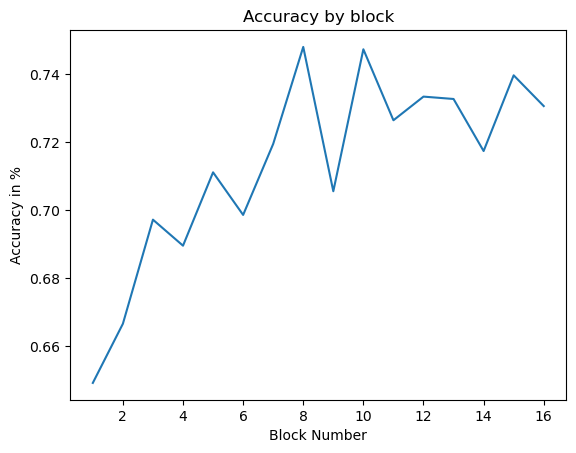

In [19]:
# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
#df_sorted = df.sort_values(by='trial')
#print(df_sorted)
acc_by_block = plt.plot(mean_block_allp)
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot

block_number
1     0.649306
2     0.666667
3     0.697222
4     0.689583
5     0.711111
6     0.698611
7     0.719444
8     0.747917
9     0.705556
10    0.747222
11    0.726389
12    0.733333
13    0.732639
14    0.717361
15    0.739583
16    0.730556
Name: acc_trial_concrete_cued, dtype: float64


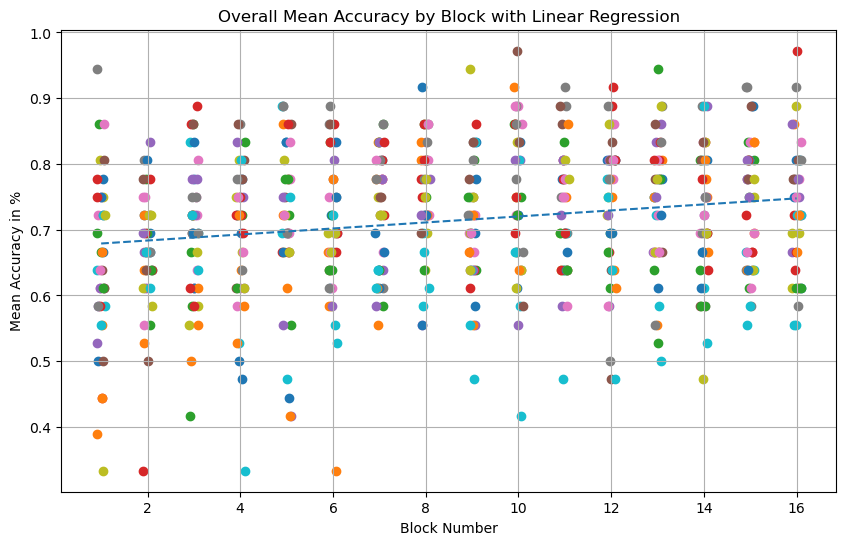

In [20]:
# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)

# Access accuracy data by block for each participant
accuracy_data_by_participant = {}

for participant_id in df['subID'].unique():
    participant_data = df[df['subID'] == participant_id]
    mean_accuracy_by_block = participant_data.groupby('block_number')['acc_trial_concrete_cued'].mean()
    accuracy_data_by_participant[participant_id] = mean_accuracy_by_block

# Create a scatterplot for each participant
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

jitter = 0.1 


for participant_id, accuracy_series in accuracy_data_by_participant.items():
    
    # Add jitter to the x-axis values
    x_values = accuracy_series.index + np.random.uniform(-jitter, jitter, len(accuracy_series))

    plt.scatter(x_values, accuracy_series, label=f'Participant {participant_id}', marker='o')
    
    # # Perform linear regression for each participant
    # slope, intercept, r_value, p_value, std_err = stats.linregress(accuracy_series.index, accuracy_series)
    # plt.plot(x_values, intercept + slope * x_values, label=f'LinReg (p={p_value:.4f})', linestyle='--')


plt.xlabel('Block Number')
plt.ylabel('Accuracy in %')
plt.title('Accuracy by Block for Each Participant')

plt.grid(True)


# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)
# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')

plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')

plt.grid(True)
plt.show()


plt.show()

block_number
1     0.649306
2     0.666667
3     0.697222
4     0.689583
5     0.711111
6     0.698611
7     0.719444
8     0.747917
9     0.705556
10    0.747222
11    0.726389
12    0.733333
13    0.732639
14    0.717361
15    0.739583
16    0.730556
Name: acc_trial_concrete_cued, dtype: float64


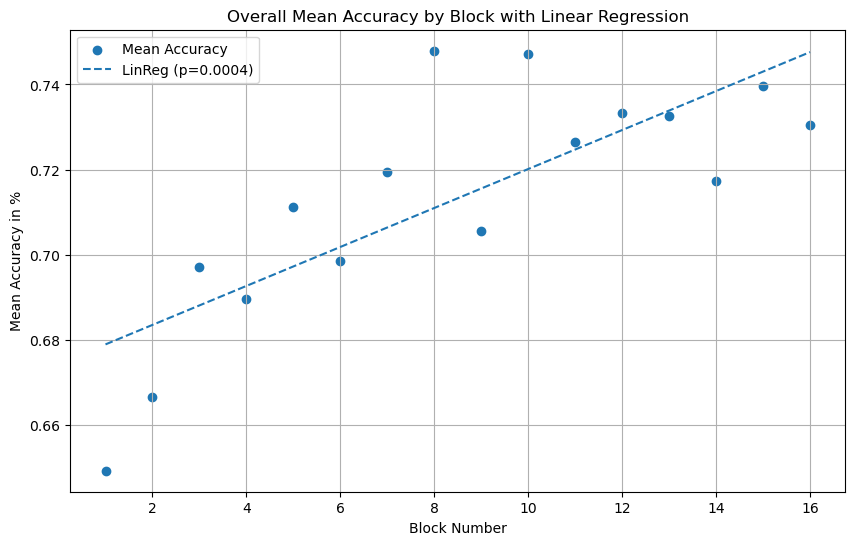

In [21]:
# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)

# Create a scatterplot for the overall mean accuracy
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

plt.scatter(mean_block_allp.index, mean_block_allp, label='Mean Accuracy', marker='o')

# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')

plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

## Accuracy depending on mnemonic distance? (position1, 2 or 3)

Can only compare those in 
- position 1 (load 1)
- position 1 (load 2)
- position 1 (load 3)
- position 2 (load 2)
- position 2 (load 3)
- position 3 (load 3)

In [22]:
# One way Anova
# might want to group the data into either all data position 1, or group them seperately for the conditions as well
# accuracy for position of item within the load conditions (mnemonic distance?, in position two and three they should be remembered better)

# Make a dictionary 

mne_dist_dict = {
    "position1/load1": 1,
    "position1/load2": 2,
    "position1/load3": 3,
    "position2/load2": 4,
    "position2/load3": 5,
    "position3/load3": 6,
}

## could actually calculate or at least list the actual distances between when the objects where shown and their test



# Distance Error
# The distances between stim1 and its test are:
## meaning only in position 1 the distance in load 1 would be 0.5s for object timeout + 0.5s for fixation cross? (need to check in the lab)
## 3.5 ???


# - Load1: 4 seconds (**error**!, it should be 1 + 3.5 seconds). ---> ## how did it end up being 4?
# - Load2: 5.5 seconds (2+ 3.5 seconds).
# - Load3: 6.5 seconds (3 + 3.5 seconds).


# Circular Stuff

## Oblique Effect

### two categories (oblique vs cardinal)

object_cued_rot
11.25     0.753212
33.75     0.740968
56.25     0.670368
78.75     0.723001
101.25    0.717839
123.75    0.673171
146.25    0.696392
168.75    0.721727
191.25    0.718399
213.75    0.704873
236.25    0.687973
258.75    0.704861
281.25    0.744986
303.75    0.678749
326.25    0.706529
348.75    0.769501
Name: acc_trial_concrete_cued, dtype: float64
mean per category:  Cardinal_Category
Cardinal    0.731709
Oblique     0.695063
Name: acc_trial_concrete_cued, dtype: float64
grouped data: object_cued_rot  Cardinal_Category
11.25            Cardinal             0.753212
33.75            Oblique              0.740968
56.25            Oblique              0.670368
78.75            Cardinal             0.723001
101.25           Cardinal             0.717839
123.75           Oblique              0.673171
146.25           Oblique              0.696392
168.75           Cardinal             0.721727
191.25           Cardinal             0.718399
213.75           Oblique            

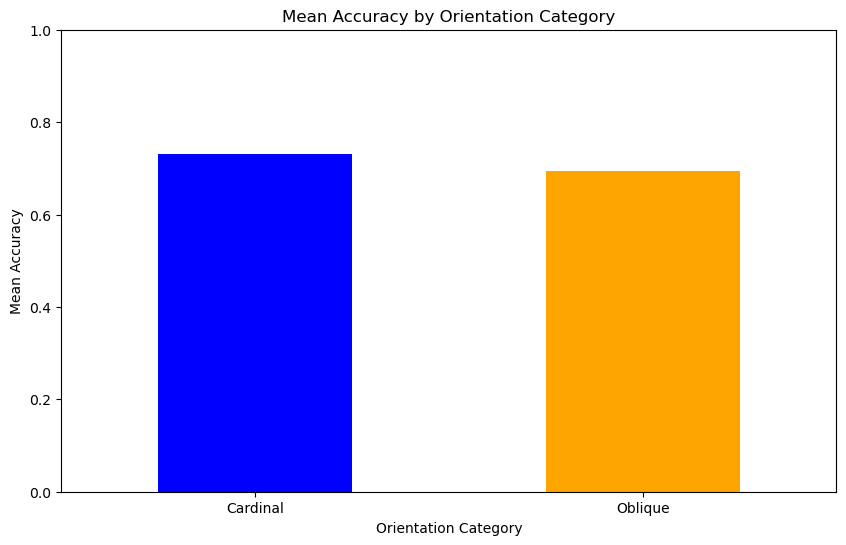

T-Test Results:
T-statistic: 3.2752302298871263
p-value: 0.005528127904269366
The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.


In [23]:
## Grouping and comparing the data according to two categories: cardinal (8 orientations closest to the cardinal axes) and oblique (remaining 8 diagonal orientations)
mean_per_ori_values = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values
mean_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean()
print(mean_per_ori)

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]

# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
print("mean per category: ", mean_per_category)

# Group data by 'object_cued_rot' and 'Cardinal_Category'
grouped_cardinal = df.groupby(['object_cued_rot', 'Cardinal_Category'])['acc_trial_concrete_cued'].mean()

print("grouped data:", grouped_cardinal)

# Reset index for easier formatting
grouped_cardinal = grouped_cardinal.reset_index()

# Organize data by 'Cardinal' and 'Oblique' categories
cardinal_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Cardinal']
oblique_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Oblique']



# # Select data for 'Cardinal' category

# # Select data for 'Oblique' category
# oblique_data2 = df.loc[df['Cardinal_Category'] == 'Oblique', 'acc_trial_concrete_cued']

#does the following line work? without df? - yes because it is within a newly stored variable
cardinal_acc = cardinal_data['acc_trial_concrete_cued']
oblique_acc = oblique_data['acc_trial_concrete_cued']

## Visualising the data 
# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_per_category.plot(kind='bar', color=['blue', 'orange'])
plt.title("Mean Accuracy by Orientation Category")
plt.xlabel("Orientation Category")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(cardinal_acc, oblique_acc)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between cardinal and oblique orientations in probe items.")

## potentially add significance to the plots (asterix)


MBP: object_cued_rot  items_presented
11.25            1                  0.847917
                 2                  0.717526
                 3                  0.698444
33.75            1                  0.789583
                 2                  0.731557
                 3                  0.703407
56.25            1                  0.783333
                 2                  0.637827
                 3                  0.588362
78.75            1                  0.800000
                 2                  0.730126
                 3                  0.636752
101.25           1                  0.818750
                 2                  0.709172
                 3                  0.625000
123.75           1                  0.737500
                 2                  0.659751
                 3                  0.621564
146.25           1                  0.764583
                 2                  0.697723
                 3                  0.630435
168.75           

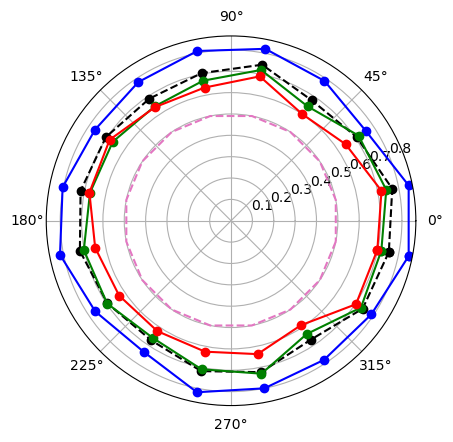

In [24]:
## Plotting the Oblique effect on a polar plot

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

acc_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

acc_df = df.groupby(by=['object_cued_rot', 'items_presented'])['acc_trial_concrete_cued'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
oriacc1 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 1].to_numpy()
oriacc2 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 2].to_numpy()
oriacc3 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 3].to_numpy()

print("acc_df:", acc_df)
print("oriacc1:", oriacc1)
print("oriacc2:", oriacc2)
print("oriacc3:", oriacc3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

acc_per_ori_circ = np.append(acc_per_ori, acc_per_ori[0])
oriacc1_circ = np.append(oriacc1, oriacc1[0])
oriacc2_circ = np.append(oriacc2, oriacc2[0])
oriacc3_circ = np.append(oriacc3, oriacc3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, acc_per_ori_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, oriacc1_circ, 'bo-')
ax.plot(-spacing_circ, oriacc2_circ, 'go-')
ax.plot(-spacing_circ, oriacc3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### 4 categories (A,B,C,D) referring to the four equal distances from cardinal axes

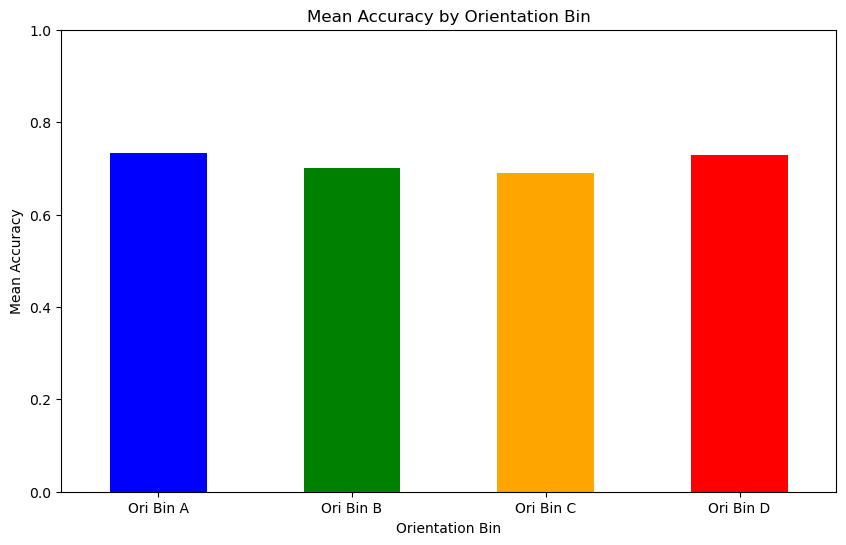

F-statistic: 12.468888768369554
P-value: 3.829002741774331e-08
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1    group2  meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Ori Bin A Ori Bin B   -0.034 0.0005 -0.0562 -0.0118   True
Ori Bin A Ori Bin C  -0.0434    0.0 -0.0656 -0.0212   True
Ori Bin A Ori Bin D  -0.0041 0.9639 -0.0264  0.0181  False
Ori Bin B Ori Bin C  -0.0094  0.694 -0.0315  0.0127  False
Ori Bin B Ori Bin D   0.0299 0.0031  0.0077  0.0521   True
Ori Bin C Ori Bin D   0.0393    0.0  0.0171  0.0614   True
----------------------------------------------------------


In [25]:
## Could also do the same and compare the four orientations per quadrant

# mean_per_ori

# # orientations closest to the cardinal axes
# orientation_subset_A = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_B = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_C = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_D = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]




# Define the orientation bins and labels
orientation_bins = {
    11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
    101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
    191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
    281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
}

# Create a new column with bin labels
df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)

columns = df.columns
column_names = df.columns.tolist()
## Visualising the data

# Calculate mean accuracy for each bin
mean_accuracies = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].mean()


# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_accuracies.plot(kind='bar', color=['blue', 'green', 'orange', 'red'])
plt.title("Mean Accuracy by Orientation Bin")
plt.xlabel("Orientation Bin")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

## check if assumptions of ANOVA are met!!!


# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")
    
    # enter tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['acc_trial_concrete_cued'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)
    print(tukey.summary())
else:
    print("The p-value is not significant, indicating no significant differences between groups.")

## could then also insert asterix whereever the data is significantly different

## Cardinal Repulsion

In [26]:
# this isnt too informative because the mean for all orientations is very close to 0.5 for all conditions

# mean clockwise proportion of all button presses
# mbp = mean button press 
mbp = df['button_press_clockwise'].mean()
print("the mean of all button presses is:", mbp)

# mean button press per condition

mbp_per_con = df.groupby('items_presented')['button_press_clockwise'].mean()
print("this is the mbp_per_con:", mbp_per_con)

# mean button press per rotation/ori
mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
print("button presses grouped by rotation:", mbp_per_ori)

the mean of all button presses is: 0.5048611111111111
this is the mbp_per_con: items_presented
1    0.506250
2    0.507292
3    0.501042
Name: button_press_clockwise, dtype: float64
button presses grouped by rotation: [0.58079784 0.46216769 0.43233865 0.40182328 0.55223881 0.47735192
 0.43771273 0.38930775 0.61867978 0.57515443 0.52989691 0.50138889
 0.63395415 0.56929638 0.51340206 0.40829234]


### Cardinal Repulsion Bias Plot (?)
For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

I think I started the following bullet points when simultaneosly reading the Memoreye paper
Calculating whether
1) a repulsion bias occured (bias away from the cardinal axes)
2)

MBP: 0.5048611111111111
MBP1: [0.55833333 0.47708333 0.4375     0.38333333 0.55833333 0.43541667
 0.40833333 0.4625     0.62708333 0.56458333 0.52291667 0.50625
 0.63958333 0.56458333 0.50833333 0.44583333]
MBP2: [0.58762887 0.47131148 0.43460765 0.43096234 0.54362416 0.50622407
 0.45548654 0.37447699 0.60649087 0.57545272 0.50411523 0.50632911
 0.64       0.58189655 0.51659751 0.38216561]
MBP3: [0.59533074 0.43887776 0.42456897 0.39102564 0.55416667 0.49048626
 0.4486166  0.33333333 0.62305987 0.58541667 0.56237219 0.49176955
 0.62131519 0.56155508 0.51521298 0.39618644]


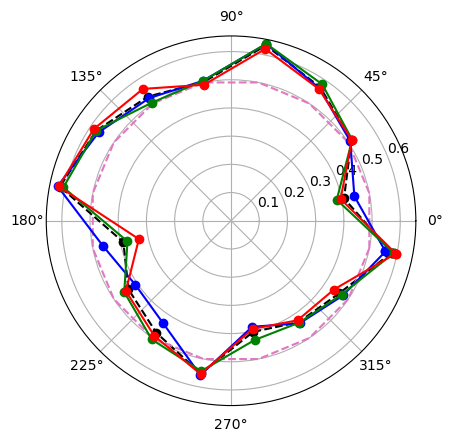

In [27]:
# Original Plot

# since I transformed the data to radians, the data is no longer between 0 and 1 but between 0.001 and 0.2 (I think). Therefore the tick labels on the plot are not reflecting the actual data. In the plot below (next code cell) I managred to transform the data back but the it looks like the 
# maximum value of 0.63 is never reached so something might be off. 
# Also the plot still looks like the opposite of what Juan was plotting. WHY???
# maybe I need to double check where the starting point of my data is. If the first point would be plotted one orientation too far into the clockwise direction it would look very different. I doubt this is what is going on though since the overall shape looks pretty good
# could I use degrees instead of radians?

# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].to_numpy()
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].to_numpy()
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].to_numpy()

print("MBP:", mbp)
print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

mbp_circ = np.append(mbp_per_ori, mbp_per_ori[0])
mbp1_circ = np.append(mbp1, mbp1[0])
mbp2_circ = np.append(mbp2, mbp2[0])
mbp3_circ = np.append(mbp3, mbp3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, mbp_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, mbp1_circ, 'bo-')
ax.plot(-spacing_circ, mbp2_circ, 'go-')
ax.plot(-spacing_circ, mbp3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### Actual Statistics or something like it on the cardinal repulsion effect

#### Cardinal Repulsion Index
not sure if this is gonna be helpful in any way, the transformation itself might be useful to see that there is repulsion at all but the index itself is kindof arbitrary. Well not completely, that there is generally 0.55 repulsion means there is basically a 5% bias .. or smething

In [28]:
# # Can I remove this?
# # Are any variables used from this cell afterwards?

# # mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean()
# print(mbp_per_ori)
# print(mbp1)
# card_repulsion_weights = np.array([1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1])

# # Mean button presses general and per condition transformed to repulsion indexes
# cardinal_index = ((mbp_per_ori @ card_repulsion_weights)+8)/16
# cardinal_index1 = ((mbp1 @ card_repulsion_weights)+8)/16
# cardinal_index2 = ((mbp2 @ card_repulsion_weights)+8)/16
# cardinal_index3 = ((mbp3 @ card_repulsion_weights)+8)/16

# print(cardinal_index)
# print(cardinal_index1)
# print(cardinal_index2)
# print(cardinal_index3)

# # print(mbp_card)

# #ä# would maybe rather need this for all 16 orientations? Is this what I have done below?

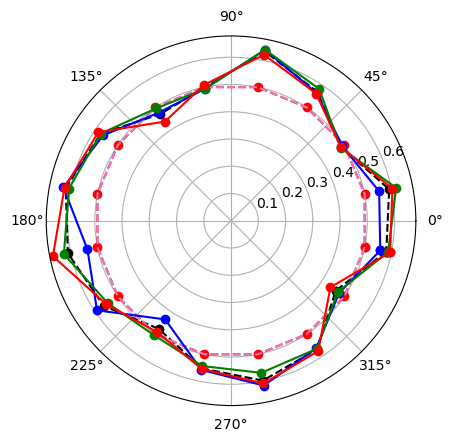

In [29]:
## Transformed cardinal repulsion data

card_repulsion_weights = np.array([1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1])

# check the orientation 101.25.. why is this at 0.5 

# do I need a for lop to transform all the data?

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)


# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

# make a mean per orientation
## card_per_ori_all was within the loop for all participants that I removed, can I add this here without the whole loop?
# what do I want here?
# below I am calculating the mean(!) button press per load condition and transforming them into the cardinal index
# since I am transforming the mean data below anyway, why would I need to transform it before aswell?
# so it seems to work without it - not sure why it was added in the first place then. Maybe I wrote these parts first and then realised that there is an easier way

# only question would be if I still need the lines that I removed to do the statistics???

# cardinal_index_per_ori = np.array(card_per_ori_all)
# mean_cardinal_index_per_ori = np.mean(cardinal_index_per_ori, axis=0)
# print(mean_cardinal_index_per_ori)

# could also do the same as above just by converting the mbp
sum_weights = [0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1]
mbp_card = (mbp_per_ori * card_repulsion_weights) + sum_weights
mbp_card_circ = np.append(mbp_card, mbp_card[0])
mbp1_card = (mbp1 * card_repulsion_weights) + sum_weights
mbp1_card_circ = np.append(mbp1_card, mbp1_card[0])
mbp2_card = (mbp2 * card_repulsion_weights) + sum_weights
mbp2_card_circ = np.append(mbp2_card, mbp2_card[0])
mbp3_card = (mbp3 * card_repulsion_weights) + sum_weights
mbp3_card_circ = np.append(mbp3_card, mbp3_card[0])


# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')


# mbp_card_circ2 = np.append(mean_cardinal_index_per_ori, mean_cardinal_index_per_ori[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, mbp_card_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)
ax.plot(-spacing_circ, unbiased_assumption, 'ro--')
# Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, mbp1_card_circ, 'bo-')
ax.plot(-spacing_circ, mbp2_card_circ, 'go-')
ax.plot(-spacing_circ, mbp3_card_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()

## Simple T-test
comparing the cardinal repulsion (transformed button press data) between the 8 cardinal positions and the 8 non-cardinal positions

In [30]:
# cardinal_oris = [11.25, 33.75, 56.25, 78.75, 101.25, 123.75, 146.25, 168.75, 191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75]
# oblique_oris = [11.25, 33.75, 56.25, 78.75, 101.25, 123.75, 146.25, 168.75, 191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75]


In [31]:
# Delete this because only bar plot?


# # data for button presses per ori

# # print(mbp_df)
# # print(mbp_per_ori)
# # print(mbp1)
# # print(mbp2)
# # print(mbp3)
# # print(mbp_card)
# # print(mbp1_card)
# # print(mbp2_card)
# # print(mbp3_card)
# # print(orientation_bins) # (dict)
# # print(orientation_subset_cardinal)


# mbp_card_card = mbp_card[[0, 3, 4, 7, 8, 11, 12, 15]]
# mbp_card_obli = mbp_card[[1, 2, 5, 6, 9, 10, 13, 14]]
# print(mbp_card_card)
# print(mbp_card_obli)

# # Calculate the mean per category
# mean_cardinal = np.mean(mbp_card_card)
# mean_oblique = np.mean(mbp_card_obli)
# print(mean_cardinal)
# print(mean_oblique)
# categories = ['Cardinal', 'Oblique']
# mean_values = [mean_cardinal, mean_oblique]

# ## Visualising the data 
# # Create a bar plot using matplotlib
# plt.figure(figsize=(10, 6))

# ## the following was "mean_per_category" - which is from the oblique plot
# plt.bar(categories, mean_values, color=['blue', 'orange'])
# plt.title("Mean Button Press by Orientation Category")
# plt.xlabel("Orientation Category")
# plt.ylabel("Mean Button Press")
# plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
# plt.xticks(rotation=0)
# plt.show()

# # Perform two-sample independent t-test
# t_statistic, p_value = stats.ttest_ind(mbp_card_card, mbp_card_obli)

# # Define the significance level (alpha)
# alpha = 0.05

# # Print the t-test results
# print("T-Test Results:")
# print("T-statistic:", t_statistic)
# print("p-value:", p_value)

# # Check if the p-value is less than alpha to determine significance
# if p_value < alpha:
#     print("The t-test indicates a significant difference in cardinal repulsion between cardinal and oblique orientations in probe items.")
# else:
#     print("The t-test does not indicate a significant difference in cardinal repuslion bias between cardinal and oblique orientations in probe items.")


/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/seaborn/categorical.py:691: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


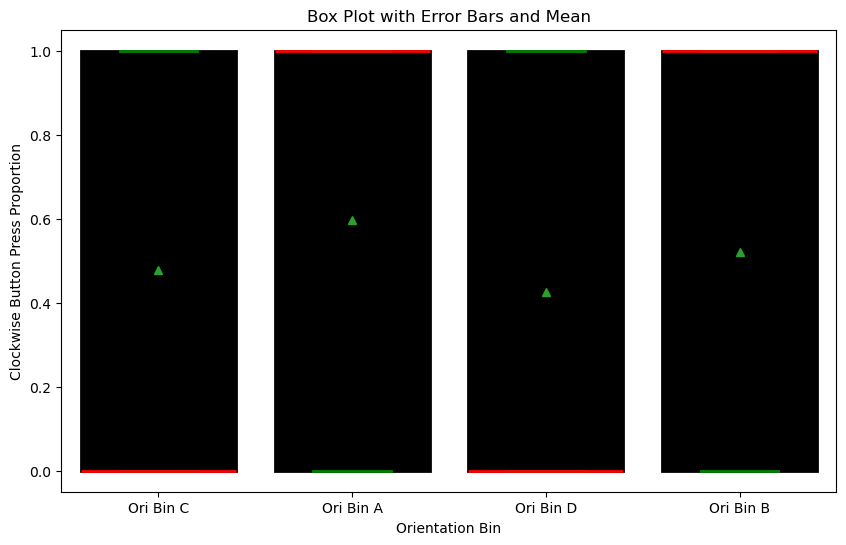

F-statistic: 121.38462709133171
P-value: 5.295030436701391e-78
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
Ori Bin A Ori Bin B  -0.0756   0.0 -0.0994 -0.0518   True
Ori Bin A Ori Bin C  -0.1179   0.0 -0.1416 -0.0941   True
Ori Bin A Ori Bin D   -0.171   0.0 -0.1948 -0.1472   True
Ori Bin B Ori Bin C  -0.0423   0.0  -0.066 -0.0186   True
Ori Bin B Ori Bin D  -0.0954   0.0 -0.1192 -0.0717   True
Ori Bin C Ori Bin D  -0.0532   0.0 -0.0769 -0.0295   True
---------------------------------------------------------


In [32]:
# Calculate the mean and standard error for each group
mean_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].mean()
std_error_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].sem()

# Create a box plot with error bars
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')

# Create a boxplot with error bars and means
bp = sns.boxplot(x='Orientation_Bin', y='button_press_clockwise', data=df, showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)

# Add error bars
for i, box in enumerate(bp.artists):
    x = i + 1
    plt.errorbar(x, mean_bp_grouped_ori_bin[i], yerr=std_error_bp_grouped_ori_bin[i], color='black', fmt='o', markersize=8)

plt.title("Box Plot with Error Bars and Mean")
plt.xlabel("Orientation Bin")
plt.ylabel("Clockwise Button Press Proportion")
plt.show()

# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['button_press_clockwise'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")

    # Enter Tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['button_press_clockwise'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)

    # Print the Tukey test results
    print(tukey.summary())

else:
    print("The p-value is not significant, indicating no significant differences between groups.")

[0.58079784 0.59817672 0.55223881 0.61069225 0.61867978 0.49861111
 0.63395415 0.59170766]
[0.46216769 0.56766135 0.47735192 0.56228727 0.57515443 0.47010309
 0.56929638 0.48659794]
0.5856072895501392
0.5213275068969989


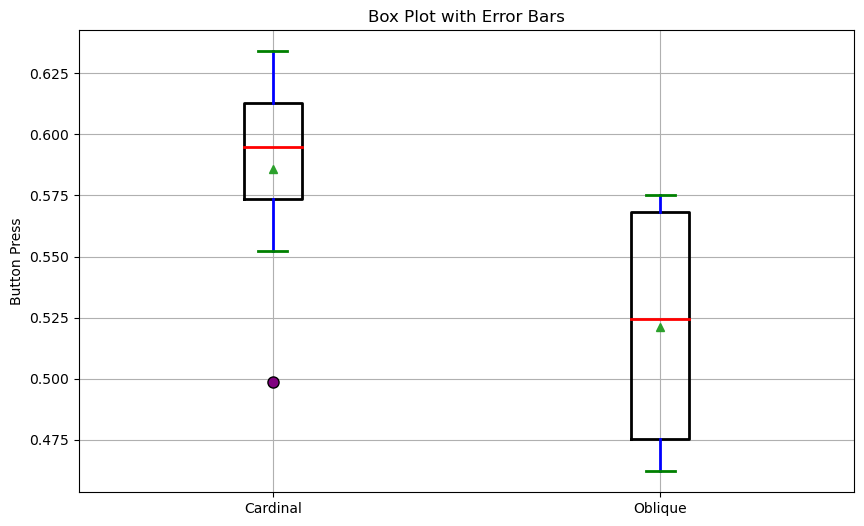

T-Test Results:
T-statistic: 2.721211210528874
p-value: 0.016554128276927302
The t-test indicates a significant difference in cardinal repulsion between cardinal and oblique orientations in probe items.


In [33]:
mbp_card_card = mbp_card[[0, 3, 4, 7, 8, 11, 12, 15]]
mbp_card_obli = mbp_card[[1, 2, 5, 6, 9, 10, 13, 14]]
print(mbp_card_card)
print(mbp_card_obli)

# Calculate the mean per category
mean_cardinal = np.mean(mbp_card_card)
mean_oblique = np.mean(mbp_card_obli)
print(mean_cardinal)
print(mean_oblique)
categories = ['Cardinal', 'Oblique']
mean_values = [mean_cardinal, mean_oblique]


# Assuming you have your data in mbp_card_card and mbp_card_obli

# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(mbp_card_card, mbp_card_obli)

# Define the significance level (alpha)
alpha = 0.05

# Create a data frame for the box plot
data = pd.DataFrame({'Cardinal': mbp_card_card, 'Oblique': mbp_card_obli})



mean_acc_grouped_ori_bin = df.groupby(['object_cued_rot', 'Orientation_Bin'])['acc_trial_concrete_cued'].mean()


# Create a box plot with error bars
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')
data.boxplot(column=['Cardinal', 'Oblique'], showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)
plt.title("Box Plot with Error Bars")
plt.ylabel("Button Press")
plt.xticks(rotation=0)
plt.show()

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in cardinal repulsion between cardinal and oblique orientations in probe items.")
else:
    print("The t-test does not indicate a significant difference in cardinal repulsion bias between cardinal and oblique orientations in probe items.")

## Cardinal Bias per Orientation Bin
using data transformed to cardinal index to calculate the difference between orientation bins

Orientation_Bin
Ori Bin A    0.596215
Ori Bin B    0.520638
Ori Bin C    0.478351
Ori Bin D    0.425191
Name: button_press_clockwise, dtype: float64
Mean transformed cardinal bias per orientation bin Orientation_Bin
Ori Bin A    0.596215
Ori Bin B    0.520638
Ori Bin C    0.521649
Ori Bin D    0.574809
Name: button_press_clockwise, dtype: float64
mbp_card - mean button press transformed for all conditions [0.58079784 0.46216769 0.56766135 0.59817672 0.55223881 0.47735192
 0.56228727 0.61069225 0.61867978 0.57515443 0.47010309 0.49861111
 0.63395415 0.56929638 0.48659794 0.59170766]


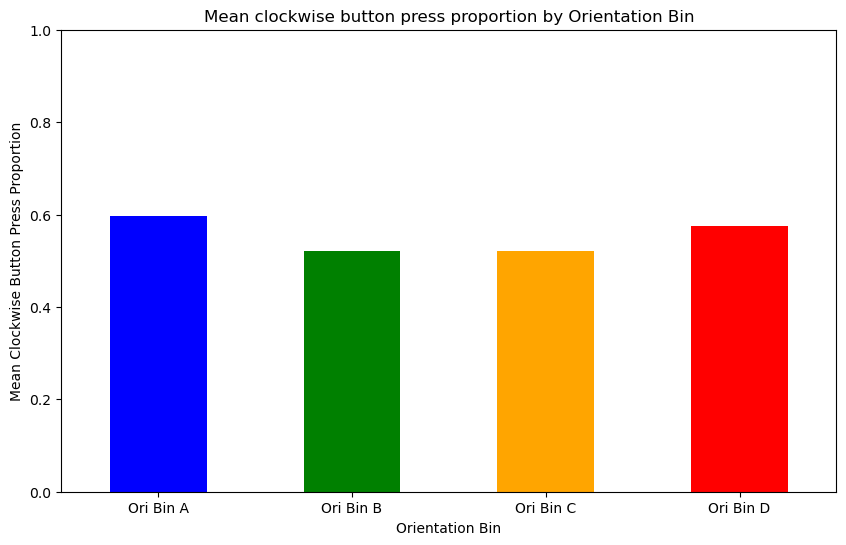

In [34]:
mean_bp_per_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].mean()
print(mean_bp_per_ori_bin)

## the following works but I am unsure if its the way it should be done... 
# could probably also use the mean card bias for all orientations and then group those by orienation bin? but maybe not so easily done in the pandas dataframe without making a new column
mean_card_bias_ori_bin = (mean_bp_per_ori_bin * [1, 1, -1, -1]) + [0, 0, 1, 1]
print("Mean transformed cardinal bias per orientation bin", mean_card_bias_ori_bin)
# use cardinal repulsion index: (mbp_card)
print("mbp_card - mean button press transformed for all conditions", mbp_card)



# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_card_bias_ori_bin.plot(kind='bar', color=['blue', 'green', 'orange', 'red'])
plt.title("Mean clockwise button press proportion by Orientation Bin")
plt.xlabel("Orientation Bin")
plt.ylabel("Mean Clockwise Button Press Proportion")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)

sns.set_style('darkgrid')
plt.show()



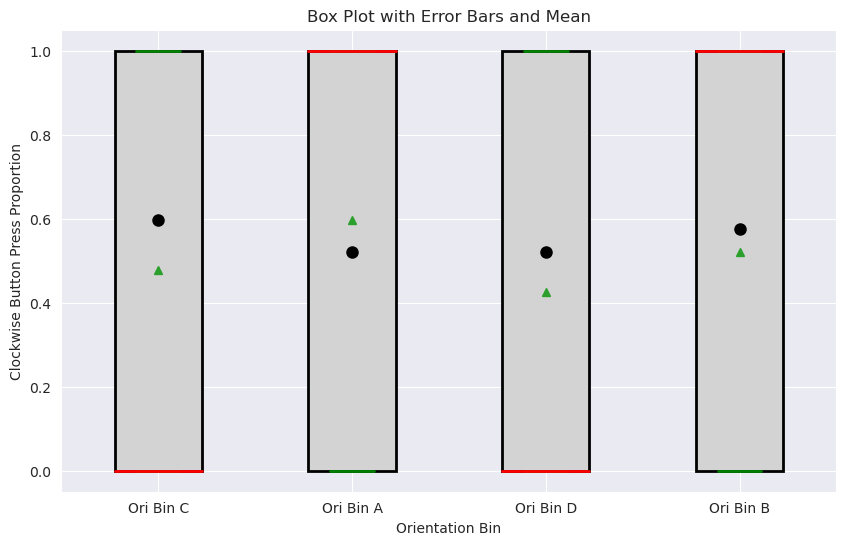

F-statistic: 121.38462709133171
P-value: 5.295030436701391e-78
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
Ori Bin A Ori Bin B  -0.0756   0.0 -0.0994 -0.0518   True
Ori Bin A Ori Bin C  -0.1179   0.0 -0.1416 -0.0941   True
Ori Bin A Ori Bin D   -0.171   0.0 -0.1948 -0.1472   True
Ori Bin B Ori Bin C  -0.0423   0.0  -0.066 -0.0186   True
Ori Bin B Ori Bin D  -0.0954   0.0 -0.1192 -0.0717   True
Ori Bin C Ori Bin D  -0.0532   0.0 -0.0769 -0.0295   True
---------------------------------------------------------
object_cued_rot
11.25     0.753212
33.75     0.740968
56.25     0.670368
78.75     0.723001
101.25    0.717839
123.75    0.673171
146.25    0.696392
168.75    0.721727
191.25    0.718399
213.75    0.704873
236.25    0.687973
258.75    0.704861
281.25    0.744986
303.75    0.67

In [35]:
## From Chat GPT
# Calculate the mean and standard error for each Orientation Bin
mean_bp_per_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].mean()
std_error_bp_per_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].sem()

# Transform the mean for cardinal bias per orientation bin
mean_card_bias_ori_bin = (mean_bp_per_ori_bin * [1, 1, -1, -1]) + [0, 0, 1, 1]

# Create a list of data for the box plot
data = [df[df['Orientation_Bin'] == bin]['button_press_clockwise'].values for bin in df['Orientation_Bin'].unique()]

# Create a box plot with error bars and means
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')
bp = plt.boxplot(data, patch_artist=True, showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)

# Add error bars
for i, box in enumerate(bp['boxes']):
    box.set(facecolor='lightgray')
    x = i + 1
    plt.errorbar(x, mean_card_bias_ori_bin[i], yerr=std_error_bp_per_ori_bin[i], color='black', fmt='o', markersize=8)

plt.xticks(range(1, len(data) + 1), df['Orientation_Bin'].unique())
plt.title("Box Plot with Error Bars and Mean")
plt.xlabel("Orientation Bin")
plt.ylabel("Clockwise Button Press Proportion")
plt.show()

# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['button_press_clockwise'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")

    # enter Tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['button_press_clockwise'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)

    # Print the Tukey test results
    print(tukey.summary())

else:
    print("The p-value is not significant, indicating no significant differences between groups.")


# This doesnt make the most sense.
# the median shown is either 1 or 0 in these cases. Not very informative
# could also do the mean for all participants individually? 
# In the previous box plot, I have the mean for every orientation but then grouped them by cardinal or oblique category so that there are 8 values in each box plot, 
# If I did the same here I could show 4 mean values per orientation bin box 




# # Define the orientation bins and labels
# orientation_bins = {
#     11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
#     101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
#     191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
#     281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
# }

# # Create a new column with bin labels
# df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)

## Visualising the data

# Calculate mean accuracy for each bin
mean_accuracies = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].mean().values

print(mean_per_ori)

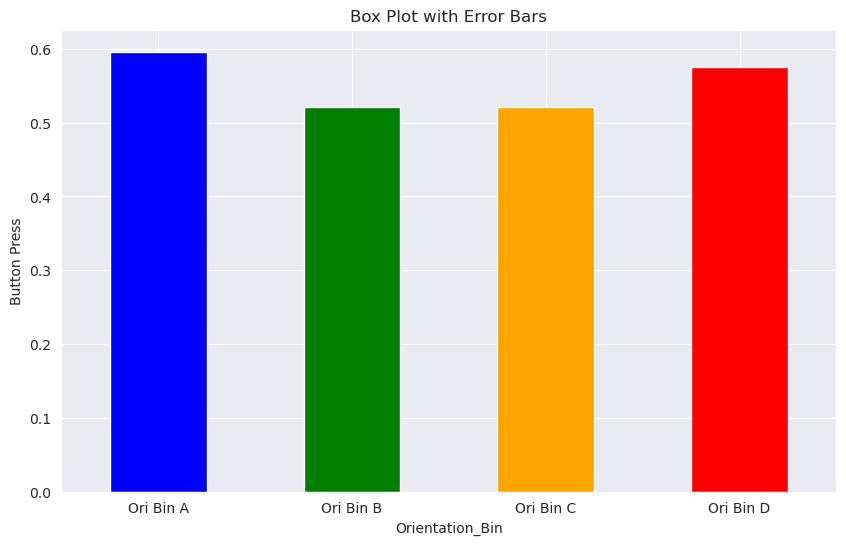

F-statistic: 121.38462709133171
P-value: 5.295030436701391e-78
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
Ori Bin A Ori Bin B  -0.0756   0.0 -0.0994 -0.0518   True
Ori Bin A Ori Bin C  -0.1179   0.0 -0.1416 -0.0941   True
Ori Bin A Ori Bin D   -0.171   0.0 -0.1948 -0.1472   True
Ori Bin B Ori Bin C  -0.0423   0.0  -0.066 -0.0186   True
Ori Bin B Ori Bin D  -0.0954   0.0 -0.1192 -0.0717   True
Ori Bin C Ori Bin D  -0.0532   0.0 -0.0769 -0.0295   True
---------------------------------------------------------


In [36]:
## Continue below with the ori bins??


# the following is stolen from above, trying to convert the plotn to a boxplot

# Create a data frame for the box plot
# data_ori_bin = pd.DataFrame({'BinA': , 'BinB': mbp_card_obli, 'BinC': })
mean_acc_grouped_ori_bin = df.groupby(['object_cued_rot', 'Orientation_Bin'])['acc_trial_concrete_cued'].mean()

# Create a box plot with error bars
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')
# mean_acc_grouped_ori_bin.plot(column=['Cardinal', 'Cardinal2', 'Oblique', 'Oblique2'], showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)
mean_card_bias_ori_bin.plot(kind='bar', color=['blue', 'green', 'orange', 'red'])
plt.title("Box Plot with Error Bars")
plt.ylabel("Button Press")
plt.xticks(rotation=0)
plt.show()

## check if assumptions of ANOVA are met!!!


# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['button_press_clockwise'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")

    # enter tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['button_press_clockwise'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)
    
    # Print the Tukey test results
    print(tukey.summary())

else:
    print("The p-value is not significant, indicating no significant differences between groups.")

## could then also insert asterix whereever the data is significantly different




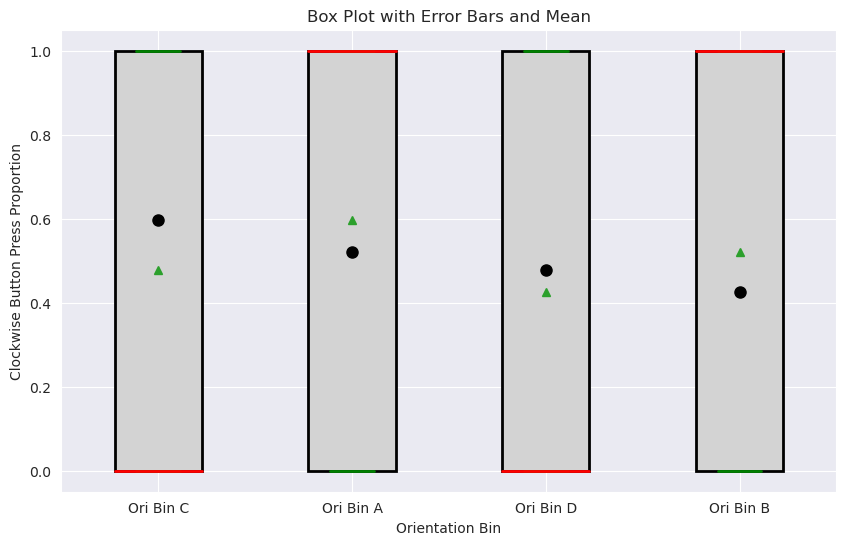

F-statistic: 121.38462709133171
P-value: 5.295030436701391e-78
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
Ori Bin A Ori Bin B  -0.0756   0.0 -0.0994 -0.0518   True
Ori Bin A Ori Bin C  -0.1179   0.0 -0.1416 -0.0941   True
Ori Bin A Ori Bin D   -0.171   0.0 -0.1948 -0.1472   True
Ori Bin B Ori Bin C  -0.0423   0.0  -0.066 -0.0186   True
Ori Bin B Ori Bin D  -0.0954   0.0 -0.1192 -0.0717   True
Ori Bin C Ori Bin D  -0.0532   0.0 -0.0769 -0.0295   True
---------------------------------------------------------


In [37]:
# Calculate the mean and standard error for each group
mean_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].mean()
std_error_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].sem()

# Create a box plot with error bars
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')

# Create the boxplot
bp = plt.boxplot([df[df['Orientation_Bin'] == bin]['button_press_clockwise'] for bin in df['Orientation_Bin'].unique()],
                 patch_artist=True, showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)

# Add error bars
for i, box in enumerate(bp['boxes']):
    box.set(facecolor='lightgray')
    x = i + 1
    plt.errorbar(x, mean_bp_grouped_ori_bin[i], yerr=std_error_bp_grouped_ori_bin[i], color='black', fmt='o', markersize=8)

plt.xticks(range(1, len(df['Orientation_Bin'].unique()) + 1), df['Orientation_Bin'].unique())
plt.title("Box Plot with Error Bars and Mean")
plt.xlabel("Orientation Bin")
plt.ylabel("Clockwise Button Press Proportion")
plt.show()

# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['button_press_clockwise'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")

    # Enter Tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['button_press_clockwise'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)

    # Print the Tukey test results
    print(tukey.summary())

else:
    print("The p-value is not significant, indicating no significant differences between groups.")

### ANOVA comparing the cardinal repulsion in the load conditions

In [38]:
# Perform one-way ANOVA
# check ines' calculations
# Do I want to compare all the orientations first and then see which of the differences are significant? But that would mean also comparing orientations that are not directly next to each other which is probably irrelevant

# So the analysis below generally shows that there is no difference between the button presses in the individual conditions. But the button presses are not a direct
# measure of the cardinal repulsion, I either need an index like the one above, or I need to only compare the orientations close to the cardinal axes 
# (maybe weighting them according to the repulsion in either clockwise or anti-clockwise direction)

## ?? should I maybe let this run on the transformed data? Would that even make a difference?

load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = stats.f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")


ANOVA Results:
F-statistic: 0.34444245088364583
p-value: 0.7086189805040015
The ANOVA test does not indicate a significant difference among the load conditions.


In [39]:
oris = []
oris_value = 11.25

while oris_value <= 360:
    oris.append(oris_value)
    oris_value = oris_value + 360/16

print(oris)

[11.25, 33.75, 56.25, 78.75, 101.25, 123.75, 146.25, 168.75, 191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75]


/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/seaborn/categorical.py:691: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


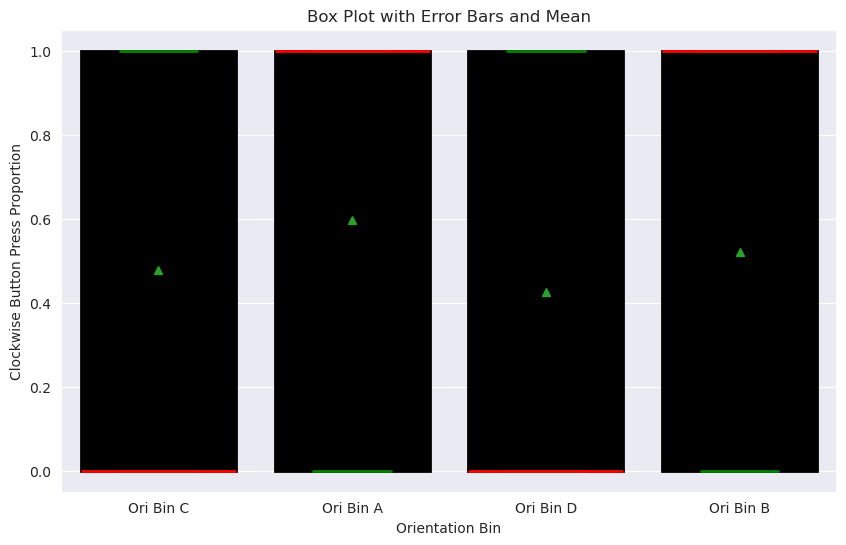

F-statistic: 121.38462709133171
P-value: 5.295030436701391e-78
The p-value is significant, indicating differences between at least two groups.
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
Ori Bin A Ori Bin B  -0.0756   0.0 -0.0994 -0.0518   True
Ori Bin A Ori Bin C  -0.1179   0.0 -0.1416 -0.0941   True
Ori Bin A Ori Bin D   -0.171   0.0 -0.1948 -0.1472   True
Ori Bin B Ori Bin C  -0.0423   0.0  -0.066 -0.0186   True
Ori Bin B Ori Bin D  -0.0954   0.0 -0.1192 -0.0717   True
Ori Bin C Ori Bin D  -0.0532   0.0 -0.0769 -0.0295   True
---------------------------------------------------------


In [40]:
# Calculate the mean and standard error for each group
mean_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].mean()
std_error_bp_grouped_ori_bin = df.groupby('Orientation_Bin')['button_press_clockwise'].sem()

# Create a box plot with error bars
plt.figure(figsize=(10, 6))
boxprops = dict(linewidth=2, color='black')
medianprops = dict(linewidth=2, color='red')
whiskerprops = dict(linewidth=2, color='blue')
capprops = dict(linewidth=2, color='green')
flierprops = dict(marker='o', markersize=8, markerfacecolor='purple')

# Create a boxplot with error bars and means
bp = sns.boxplot(x='Orientation_Bin', y='button_press_clockwise', data=df, showmeans=True, boxprops=boxprops, medianprops=medianprops, whiskerprops=whiskerprops, capprops=capprops, flierprops=flierprops)

# Add error bars
for i, box in enumerate(bp.artists):
    x = i + 1
    plt.errorbar(x, mean_bp_grouped_ori_bin[i], yerr=std_error_bp_grouped_ori_bin[i], color='black', fmt='o', markersize=8)

plt.title("Box Plot with Error Bars and Mean")
plt.xlabel("Orientation Bin")
plt.ylabel("Clockwise Button Press Proportion")
plt.show()

# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['button_press_clockwise'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")

    # Enter Tukey test
    # Perform Tukey's post hoc test
    tukey = pairwise_tukeyhsd(endog=df['button_press_clockwise'],
                              groups=df['Orientation_Bin'],
                              alpha=alpha)

    # Print the Tukey test results
    print(tukey.summary())

else:
    print("The p-value is not significant, indicating no significant differences between groups.")

## Cardinal Bias Index alla Bernhard   

In [45]:
# oris
# df.groupby('object_cued_rot')['button_press_clockwise']
# mean button presses per orienation
print(mbp_per_ori)
print(mbp1)
print(mbp2)
print(mbp3)

print(mbp_df)

print(mbp_per_con)
# might need this data per participant?

[0.58079784 0.46216769 0.43233865 0.40182328 0.55223881 0.47735192
 0.43771273 0.38930775 0.61867978 0.57515443 0.52989691 0.50138889
 0.63395415 0.56929638 0.51340206 0.40829234]
[0.55833333 0.47708333 0.4375     0.38333333 0.55833333 0.43541667
 0.40833333 0.4625     0.62708333 0.56458333 0.52291667 0.50625
 0.63958333 0.56458333 0.50833333 0.44583333]
[0.58762887 0.47131148 0.43460765 0.43096234 0.54362416 0.50622407
 0.45548654 0.37447699 0.60649087 0.57545272 0.50411523 0.50632911
 0.64       0.58189655 0.51659751 0.38216561]
[0.59533074 0.43887776 0.42456897 0.39102564 0.55416667 0.49048626
 0.4486166  0.33333333 0.62305987 0.58541667 0.56237219 0.49176955
 0.62131519 0.56155508 0.51521298 0.39618644]
object_cued_rot  items_presented
11.25            1                  0.558333
                 2                  0.587629
                 3                  0.595331
33.75            1                  0.477083
                 2                  0.471311
                 3       

In [ ]:
## in this I am trying to get the cardinal repuslion data per participant to then calculate a single number index for every participant
# am I able to include the 

partis = df['subID'].unique()

card_repulsion_per_participant = []

for i in partis:



    # all conditions
    participant_data = df.loc[df['subID'] == i, 'button_press_clockwise']


    # something like this 
    mean_per_pp = participant_data.mean()

    # this shouldnt be results but rather something called a df for participant data for every orientation, maybe wont need to append anything 
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

    # then I can directly do the index by subtracting the correct orienation values 

    # condition 1
    
    # condition 2

    # condition 3

    # then append the results for every single participant

In [58]:
for i in good_partis:

    # all conditions
    participant_data = df.loc[df['subID'] == i, ['button_press_clockwise', 'object_cued_rot', 'items_presented']]

    # I need to then mean the data per participant (within the loop it is single participant data) by ori - so I have a mean per ori per pp
    
    grouped_data = participant_data.groupby(['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
    
    # all conditions

    # condition 1
    
    # condition 2

    # condition 3

    # print(i, participant_data)
    print(i, grouped_data)

Z16JQR object_cued_rot  items_presented
11.25            1                  0.416667
                 2                  0.733333
                 3                  0.450000
33.75            1                  0.750000
                 2                  0.750000
                 3                  0.300000
56.25            1                  0.500000
                 2                  0.444444
                 3                  0.529412
78.75            1                  0.416667
                 2                  0.500000
                 3                  0.142857
101.25           1                  0.583333
                 2                  0.666667
                 3                  0.545455
123.75           1                  0.416667
                 2                  0.900000
                 3                  0.800000
146.25           1                  0.500000
                 2                  0.571429
                 3                  0.636364
168.75         